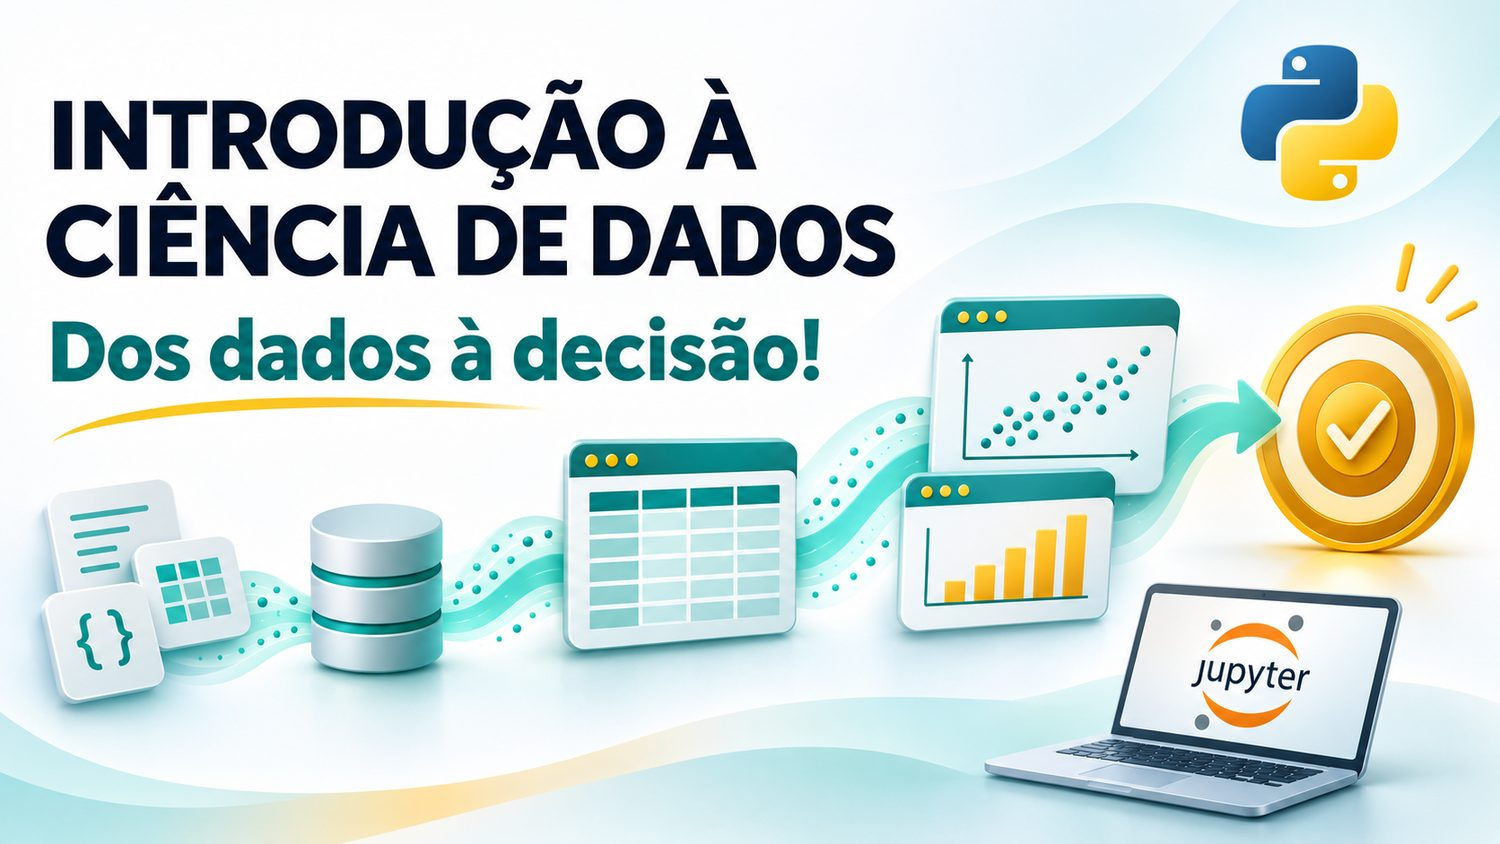

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/projeto_dados_reais/03_Decidir_Verificar_e_Comunicar.ipynb)

# Projeto com dados reais · Parte 3 – Decidir, verificar e comunicar

A parte 2 acabou com um resultado: em 2010, ordenar a lista por uma regra de uma frase dá cerca de 16 subscrições em 20 chamadas, contra cerca de 10 ao acaso, e um modelo não faz melhor. Falta o trabalho do módulo 8: perceber o que se pode prometer com este resultado, para quem funciona, que dados pessoais estão em jogo, e como se entrega tudo isto a quem decide.

> **Objetivos:** ler o resultado para várias capacidades; medir o que mudou entre o desenvolvimento e o teste; verificar se as probabilidades de um modelo resistem a essa mudança; acompanhar o desempenho mês a mês; avaliar por grupo etário; medir o risco de reidentificação e aplicar a minimização; preencher a ficha da solução e escrever o relatório de uma página.

**Pré-requisitos:** partes 1 e 2 do projeto; módulo 8 (capítulos 1 a 6).

**Duração sugerida:** 2 horas e meia.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Cores usadas em todo o tutorial (sempre com o mesmo significado)
AZUL, VERDE, VIOLETA, LARANJA = "#2a78d6", "#1baf7a", "#6250d6", "#eb6834"
BOM, MAU, AVISO, CINZA, TINTA = "#0ca30c", "#d03b3b", "#fab219", "#b4bdc8", "#131c26"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})


def tela(largura, altura, tamanho=(10, 3)):
    """Cria uma figura vazia, sem eixos, para desenhar esquemas."""
    fig, ax = plt.subplots(figsize=tamanho)
    ax.set_xlim(0, largura)
    ax.set_ylim(0, altura)
    ax.axis("off")
    return fig, ax


def caixa(ax, x, y, largura, altura, texto, cor, tamanho=10, negrito=False):
    """Desenha uma caixa arredondada com texto centrado."""
    ax.add_patch(FancyBboxPatch((x, y), largura, altura, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor + "30", ec=cor, lw=1.6))
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", color=TINTA,
            fontsize=tamanho, linespacing=1.45, fontweight="bold" if negrito else "normal")


def seta(ax, inicio, fim, cor="#465463", **opcoes):
    """Desenha uma seta entre dois pontos."""
    opcoes.setdefault("arrowstyle", "-|>")
    ax.add_patch(FancyArrowPatch(inicio, fim, mutation_scale=14, color=cor, lw=1.5, **opcoes))

As duas células seguintes repetem, sem alterações, o que as partes 1 e 2 construíram: os dados preparados, a divisão no tempo, a regra, a regressão logística e a métrica da decisão.

In [2]:
import os

FICHEIRO = "dados/bank-additional-full.csv"
ENDERECO = ("https://raw.githubusercontent.com/ricardoluizdasilva/mestrado_ai_estudos/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20"
            "Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/projeto_dados_reais/" + FICHEIRO)
NOMES = {"age": "idade", "job": "profissao", "marital": "estado_civil", "education": "escolaridade", "default": "incumprimento",
         "housing": "credito_habitacao", "loan": "credito_pessoal", "contact": "meio_contacto", "month": "mes",
         "day_of_week": "dia_semana", "duration": "duracao_s", "campaign": "contactos_campanha", "pdays": "dias_desde_anterior",
         "previous": "contactos_anteriores", "poutcome": "resultado_anterior", "emp.var.rate": "var_emprego",
         "cons.price.idx": "indice_precos", "cons.conf.idx": "indice_confianca", "euribor3m": "euribor_3m",
         "nr.employed": "n_empregados", "y": "subscreveu"}
PERIODOS = pd.to_datetime(["2008-05", "2008-06", "2008-07", "2008-08", "2008-10", "2008-11", "2008-12", "2009-03", "2009-04",
                           "2009-05", "2009-06", "2009-07", "2009-08", "2009-09", "2009-10", "2009-11", "2009-12", "2010-03",
                           "2010-04", "2010-05", "2010-06", "2010-07", "2010-08", "2010-09", "2010-10", "2010-11"])


def carregar():
    """Lê o ficheiro original: da pasta dados/, se existir, ou do repositório do tutorial."""
    bruto = pd.read_csv(FICHEIRO if os.path.exists(FICHEIRO) else ENDERECO, sep=";")
    assert bruto.shape == (41188, 21), "O ficheiro não tem as dimensões esperadas."
    return bruto


def preparar(bruto):
    """Aplica as decisões da parte 1: nomes em português, período reconstruído, alvo em 0 e 1, 999 como valor em falta."""
    t = bruto.rename(columns=NOMES)
    bloco = (t["mes"] != t["mes"].shift()).cumsum().to_numpy()
    assert bloco.max() == len(PERIODOS), "A sequência de meses não é a esperada."
    t["periodo"] = PERIODOS[bloco - 1]
    t["subscreveu"] = (t["subscreveu"] == "yes").astype(int)
    t["dias_desde_anterior"] = t["dias_desde_anterior"].replace(999, np.nan)
    return t


dados = preparar(carregar())
print(f"{len(dados)} contactos, de {dados['periodo'].min():%m/%Y} a {dados['periodo'].max():%m/%Y}")

41188 contactos, de 05/2008 a 11/2010


In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

desenvolvimento = dados[dados["periodo"] < "2010-01-01"]
teste = dados[dados["periodo"] >= "2010-01-01"]
CLIENTE = ["idade", "profissao", "estado_civil", "escolaridade", "incumprimento", "credito_habitacao", "credito_pessoal"]
CONTACTOS = ["meio_contacto", "dia_semana", "contactos_campanha", "contactos_anteriores", "resultado_anterior"]
colunas = CLIENTE + CONTACTOS


def regra(tabela):
    """Pontuação da regra: 2 pontos por subscrição anterior, 1 ponto por telemóvel."""
    return 2.0 * (tabela["resultado_anterior"] == "success") + 1.0 * (tabela["meio_contacto"] == "cellular")


def por_100(y, pontuacao, fracao=0.2, rng=None):
    """Subscrições obtidas por cada 100 clientes da lista, telefonando à fração com maior pontuação."""
    y, pontuacao = np.asarray(y), np.asarray(pontuacao, dtype=float)
    rng = rng if rng is not None else np.random.default_rng(0)
    ordem = np.lexsort((rng.random(len(y)), -pontuacao))
    return 100 * y[ordem[:int(round(fracao * len(y)))]].sum() / len(y)


def media_por_100(y, pontuacao, fracao=0.2, repeticoes=200):
    rng = np.random.default_rng(1)
    return np.mean([por_100(y, pontuacao, fracao, rng) for _ in range(repeticoes)])


numericas = [c for c in colunas if pd.api.types.is_numeric_dtype(dados[c])]
nominais = [c for c in colunas if c not in numericas]
modelo = make_pipeline(ColumnTransformer([("num", StandardScaler(), numericas),
                                          ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), nominais)]),
                       LogisticRegression(max_iter=2000)).fit(desenvolvimento[colunas], desenvolvimento["subscreveu"])

y_teste = teste["subscreveu"].to_numpy()
p_regra = regra(teste).to_numpy()
p_modelo = modelo.predict_proba(teste[colunas])[:, 1]
print(f"Regra: {media_por_100(y_teste, p_regra):.1f} | modelo: {media_por_100(y_teste, p_modelo):.1f} subscrições por 100 clientes, com 20 chamadas")

Regra: 15.7 | modelo: 15.5 subscrições por 100 clientes, com 20 chamadas


## Da ordenação à decisão

A capacidade de 20% veio do enquadramento, mas a direção comercial vai querer saber o que acontece com mais ou menos chamadas. O gráfico seguinte responde para todas as capacidades de uma vez. A linha a tracejado é o máximo possível: acertar em todas as chamadas, até esgotar os clientes que subscrevem.

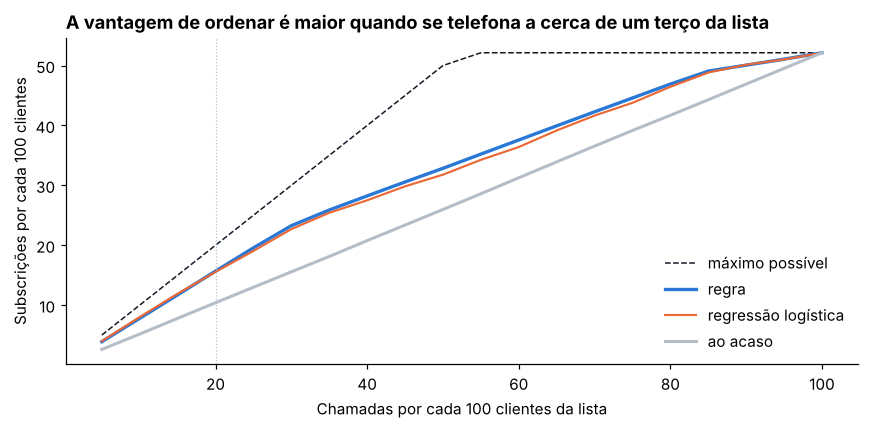

,ao acaso,regra,regressão logística,ganho_da_regra
10.0,5.2,7.8,8.0,2.6
20.0,10.4,15.7,15.5,5.3
30.0,15.6,23.3,22.7,7.7
50.0,26.0,32.8,31.8,6.9
100.0,52.1,52.1,52.1,0.0


In [4]:
fracoes = np.arange(0.05, 1.001, 0.05)
taxa = 100 * y_teste.mean()
curvas = pd.DataFrame({"ao acaso": [media_por_100(y_teste, np.zeros(len(y_teste)), f, 50) for f in fracoes],
                       "regra": [media_por_100(y_teste, p_regra, f, 50) for f in fracoes],
                       "regressão logística": [media_por_100(y_teste, p_modelo, f, 50) for f in fracoes]}, index=(100 * fracoes).round())

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(curvas.index, np.minimum(curvas.index, taxa), color=TINTA, ls="--", lw=1, label="máximo possível")
ax.plot(curvas.index, curvas["regra"], color=AZUL, lw=2.2, label="regra")
ax.plot(curvas.index, curvas["regressão logística"], color=LARANJA, lw=1.4, label="regressão logística")
ax.plot(curvas.index, curvas["ao acaso"], color=CINZA, lw=2, label="ao acaso")
ax.axvline(20, color=CINZA, lw=0.8, ls=":")
ax.set_xlabel("Chamadas por cada 100 clientes da lista")
ax.set_ylabel("Subscrições por cada 100 clientes")
ax.set_title("A vantagem de ordenar é maior quando se telefona a cerca de um terço da lista")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

curvas.loc[[10, 20, 30, 50, 100]].assign(ganho_da_regra=lambda t: t["regra"] - t["ao acaso"]).round(1)

- As curvas da regra e do modelo andam quase sobrepostas, com a regra ligeiramente acima entre 30 e 70 chamadas: o empate da parte 2 não era um acaso dos 20%.
- O ganho da regra sobre o acaso cresce até cerca de 30 chamadas (7,7 subscrições a mais) e depois diminui. A razão está na composição da lista: perto de um terço dos clientes de 2010 já tinha subscrito antes, e é nesse grupo que a regra acerta mais. Esgotado o grupo, sobram os clientes de telemóvel sem histórico, que se distinguem menos dos restantes.
- Com 100 chamadas, a ordem deixa de interessar: telefona-se a todos.
- A distância ao máximo possível (20 subscrições em 20 chamadas) mostra o que fica por apanhar: com estas colunas, cerca de uma em cada cinco chamadas não dá em subscrição.

Se a capacidade puder passar de 20 para 30 chamadas por 100 clientes, o ganho da regra sobe de 5,3 para 7,7 subscrições. É uma informação útil para quem decide o tamanho da equipa.

## O que mudou entre o desenvolvimento e o teste

A parte 1 mostrou que as campanhas mudaram. Antes de prometer que o resultado de 2010 se repete, convém medir **em quê** a lista de 2010 difere das anteriores.

In [5]:
def retrato(tabela):
    return pd.Series({"chamadas por mês": len(tabela) / tabela["periodo"].nunique(),
                      "subscrevem (%)": 100 * tabela["subscreveu"].mean(),
                      "com subscrição anterior (%)": 100 * (tabela["resultado_anterior"] == "success").mean(),
                      "contactados por telemóvel (%)": 100 * (tabela["meio_contacto"] == "cellular").mean(),
                      "com 60 anos ou mais (%)": 100 * (tabela["idade"] >= 60).mean(),
                      "estudantes ou reformados (%)": 100 * tabela["profissao"].isin(["student", "retired"]).mean()})


mudanca = pd.DataFrame({"2008": retrato(dados[dados["periodo"].dt.year == 2008]),
                        "2009": retrato(dados[dados["periodo"].dt.year == 2009]),
                        "2010 (teste)": retrato(teste)})
mudanca.round(1)

,2008,2009,2010 (teste)
chamadas por mês,3955.7,1144.0,228.7
subscrevem (%),4.8,19.5,52.1
com subscrição anterior (%),0.1,6.0,31.5
contactados por telemóvel (%),50.5,91.8,81.1
com 60 anos ou mais (%),0.6,5.9,16.8
estudantes ou reformados (%),3.6,9.8,23.5


A lista de 2010 é outra população:

- É muito mais pequena: cerca de 230 chamadas por mês, contra quase 4 000 em 2008.
- **Um em cada três clientes já tinha subscrito numa campanha anterior.** Em 2008, era um em cada mil.
- Tem muito mais clientes com 60 anos ou mais (17%, contra menos de 1%) e mais estudantes e reformados.

Isto é coerente com a hipótese de que o banco passou a telefonar sobretudo a clientes que já conhecia. Não a prova, e a documentação não esclarece.

Para a decisão, o que interessa é a consequência: **a regra funciona bem em 2010 porque a lista de 2010 tem muitos clientes com subscrição anterior**. Numa lista como a de 2008, quase sem histórico, a regra ficaria reduzida a «primeiro os telemóveis», e o ganho seria muito menor. O resultado não é uma propriedade da regra sozinha: é da regra aplicada a um certo tipo de lista.

## As probabilidades não sobrevivem à mudança

A regressão logística devolve probabilidades, e é tentador usá-las: «este cliente tem 15% de probabilidade de subscrever». O módulo 5 (capítulo 3) ensinou a verificar a calibração: entre os clientes a quem o modelo dá cerca de 15%, subscrevem cerca de 15%?

In [6]:
escaloes = pd.cut(p_modelo, [0, 0.1, 0.2, 0.4, 0.6, 1.0])
calibracao = pd.DataFrame({"prevista": p_modelo, "observada": y_teste}).groupby(escaloes, observed=True).agg(
    clientes=("observada", "size"), prevista=("prevista", "mean"), observada=("observada", "mean"))
calibracao.round(2)

,clientes,prevista,observada
"(0.0, 0.1]",422,0.07,0.28
"(0.1, 0.2]",669,0.13,0.48
"(0.2, 0.4]",313,0.27,0.45
"(0.4, 0.6]",274,0.51,0.69
"(0.6, 1.0]",380,0.74,0.80


Não. Entre os 669 clientes a quem o modelo atribui cerca de 13%, subscreveram 48%. No escalão mais baixo, o modelo prevê 7% e observam-se 28%. Só no topo os dois valores se aproximam (74% previstos, 80% observados).

O modelo aprendeu as probabilidades numa época em que 9% dos contactados subscreviam, e está a ser usado numa em que subscrevem 52%. A **ordem** aguenta-se razoavelmente: os escalões de cima têm mais subscrições do que os de baixo, ainda que o segundo e o terceiro apareçam trocados. Os **valores** estão errados, quase sempre por muito.

A regra não devolve probabilidades, mas o mesmo problema aparece se alguém lhe quiser associar taxas.

In [7]:
grupos = pd.DataFrame({"desenvolvimento": desenvolvimento.assign(pontos=regra(desenvolvimento)).groupby("pontos")["subscreveu"].mean(),
                       "teste": teste.assign(pontos=regra(teste)).groupby("pontos")["subscreveu"].mean()})
grupos.index = ["fixo, sem subscrição anterior", "telemóvel, sem subscrição anterior", "fixo, com subscrição anterior", "telemóvel, com subscrição anterior"]
grupos.round(2)

,desenvolvimento,teste
"fixo, sem subscrição anterior",0.04,0.20
"telemóvel, sem subscrição anterior",0.11,0.47
"fixo, com subscrição anterior",0.59,0.67
"telemóvel, com subscrição anterior",0.54,0.78


As taxas de todos os grupos subiram do desenvolvimento para o teste, e nos clientes sem subscrição anterior passaram para o quádruplo ou mais (de 4% para 20%, de 11% para 47%). Quem tivesse prometido, com base no desenvolvimento, que «11% dos clientes de telemóvel subscrevem» teria errado por muito.

O que se manteve foi o essencial da ordem: os clientes com subscrição anterior ficam acima dos outros, e, entre os que não a têm, o telemóvel fica acima do fixo.

É isto que quer dizer «a ordenação resistiu à mudança e as probabilidades não». Na prática, define o que se pode prometer: **«telefonar por esta ordem dá mais subscrições do que telefonar ao acaso»**, e nunca «tantos por cento deste grupo vão subscrever».

## Acompanhar, mês a mês

Uma solução que entra em uso tem de ser vigiada (módulo 8, capítulo 4). Com a regra, o acompanhamento é simples: em cada mês, comparar o que a regra apanha com o que se apanharia ao acaso.

In [8]:
linhas = []
for periodo, mes in teste.groupby("periodo"):
    y = mes["subscreveu"].to_numpy()
    linhas.append({"mês": f"{periodo:%m/%Y}", "clientes": len(mes), "subscrevem (%)": 100 * y.mean(),
                   "com subscrição anterior (%)": 100 * (mes["resultado_anterior"] == "success").mean(),
                   "ao acaso": media_por_100(y, np.zeros(len(y))), "regra": media_por_100(y, regra(mes).to_numpy())})
mensal = pd.DataFrame(linhas).set_index("mês")
mensal["ganho"] = mensal["regra"] - mensal["ao acaso"]
mensal.round(1)

,clientes,subscrevem (%),com subscrição anterior (%),ao acaso,regra,ganho
mês,,,,,,
03/2010,264,56.8,29.5,11.3,16.5,5.1
04/2010,174,55.7,27.0,11.1,14.5,3.4
05/2010,212,57.5,35.8,11.4,16.2,4.8
06/2010,229,46.7,32.8,9.4,14.6,5.2
07/2010,311,56.6,31.2,11.3,15.1,3.8
08/2010,233,51.5,30.9,10.4,18.3,7.8
09/2010,303,49.5,31.4,9.8,16.5,6.7
10/2010,204,45.6,33.8,9.2,15.1,5.9
11/2010,128,45.3,30.5,9.3,12.9,3.6


A regra ficou acima do acaso nos nove meses, com um ganho entre 3,4 e 7,8 subscrições por 100 clientes. Cada mês tem entre 128 e 311 clientes, e com tão poucos casos parte desta variação é ruído: um mês isolado não chega para concluir que a regra melhorou ou piorou. É por isso que a ficha, mais abaixo, propõe olhar para três meses seguidos.

A coluna «com subscrição anterior» é o sinal mais útil para vigiar. Conhece-se logo no início do mês, antes de haver resultados, e manteve-se entre 27% e 36% durante todo o ano. Se cair muito, a lista deixou de se parecer com aquela em que a regra foi avaliada (módulo 8, capítulo 4: deriva das entradas).

## Para quem funciona

O módulo 8 (capítulo 5) pede duas coisas antes de usar um sistema que escolhe pessoas: ver os resultados por grupo, e perguntar se ser escolhido ajuda ou penaliza. A regra não usa a idade, mas isso não garante que trate todas as idades da mesma maneira: se o histórico dos clientes variar com a idade, a regra herda essa diferença. É preciso medir, e convém medir também o que faria o modelo.

In [9]:
def quem_e_chamado(pontuacao, fracao=0.2):
    """Indica, para cada cliente do teste, se fica entre os primeiros da lista (empates desfeitos ao acaso)."""
    ordem = np.lexsort((np.random.default_rng(5).random(len(pontuacao)), -pontuacao))
    chamado = np.zeros(len(pontuacao), dtype=bool)
    chamado[ordem[:int(round(fracao * len(pontuacao)))]] = True
    return chamado


idades = pd.cut(teste["idade"], [0, 29, 44, 59, 120], labels=["menos de 30", "30 a 44", "45 a 59", "60 ou mais"])
por_idade = pd.DataFrame({"subscreveu": y_teste, "anterior": (teste["resultado_anterior"] == "success").to_numpy(),
                          "regra": quem_e_chamado(p_regra), "modelo": quem_e_chamado(p_modelo)}).groupby(idades.to_numpy(), observed=True).agg(
    clientes=("subscreveu", "size"), subscrevem=("subscreveu", "mean"), com_subscricao_anterior=("anterior", "mean"),
    chamados_pela_regra=("regra", "mean"), chamados_pelo_modelo=("modelo", "mean")).reindex(idades.cat.categories)
(100 * por_idade.drop(columns="clientes")).round(0).assign(clientes=por_idade["clientes"])

,subscrevem,com_subscricao_anterior,chamados_pela_regra,chamados_pelo_modelo,clientes
menos de 30,49.0,33.0,20.0,23.0,495
30 a 44,51.0,30.0,20.0,16.0,821
45 a 59,54.0,31.0,19.0,18.0,397
60 ou mais,57.0,33.0,21.0,28.0,345


**A regra telefona a cerca de 20% dos clientes de cada escalão** (entre 19% e 21%): não favorece nem evita nenhuma idade. Acontece porque a proporção de clientes com subscrição anterior é quase a mesma em todos os escalões (30% a 33%), e é nisso que a regra se apoia.

O modelo, que usa a idade e a profissão, comporta-se de outra maneira: telefona a 28% dos clientes com 60 anos ou mais e a 16% dos que têm entre 30 e 44. E, como a parte 2 mostrou, não apanha mais subscrições por isso. É mais um argumento a favor da regra: o mesmo resultado, sem tratar as idades de forma diferente.

**Ajuda ou penaliza?** Receber a chamada é receber uma oferta, e não uma penalização. Mas chamadas comerciais repetidas também são um custo para quem as recebe, e a parte 1 encontrou um cliente com 56 contactos numa só campanha. Daqui saem dois cuidados que os dados não resolvem:

- **Regras de contacto.** Um limite de tentativas por cliente e o respeito por quem pede para não ser contactado têm de existir antes de qualquer ordenação.
- **Quem entra na lista.** Os cinco clientes com 17 anos são todos estudantes, foram contactados em 2009, e dois subscreveram. Ordenar a lista não responde à pergunta de saber se deviam lá estar. Essa decisão é anterior, e fica fora do âmbito desta solução.

## Dados pessoais

O ficheiro não tem nomes nem números de cliente, e os autores já retiraram atributos por privacidade. Isso não o torna anónimo. O módulo 8 (capítulo 6) chamou **quase-identificadores** às colunas que, combinadas, podem apontar para uma pessoa. Aqui há pelo menos quatro: idade, profissão, estado civil e escolaridade.

In [10]:
def k_anonimato(tabela, quase):
    """Tamanho do grupo de cada linha: quantas pessoas partilham os mesmos quase-identificadores."""
    return tabela.groupby(quase, observed=True)[quase[0]].transform("size")


quase = ["idade", "profissao", "estado_civil", "escolaridade"]
tamanho = k_anonimato(dados, quase)
print(f"Linhas únicas nestes quatro atributos: {(tamanho == 1).sum()}")
print(f"Linhas em grupos com menos de 5: {(tamanho < 5).sum()} ({(tamanho < 5).mean():.1%})")
dados.loc[tamanho == 1, quase].head(3)

Linhas únicas nestes quatro atributos: 1254
Linhas em grupos com menos de 5: 5463 (13.3%)


,idade,profissao,estado_civil,escolaridade
22,55,retired,single,high.school
42,38,admin.,single,professional.course
53,53,admin.,single,professional.course


Há 1 254 linhas únicas nestes quatro atributos, e mais de 5 000 (13% do ficheiro) em grupos com menos de cinco pessoas. Quem souber a idade, a profissão, o estado civil e a escolaridade de um cliente daquele banco pode, nesses casos, encontrar a linha e ficar a saber se a pessoa tem créditos, se está em incumprimento e se subscreveu o depósito. Com uma ressalva: quem procura não tem a certeza de que a pessoa está no ficheiro.

Três consequências para o trabalho:

1. **Tratam-se como dados pessoais**, mesmo sem nomes: acesso limitado, sem cópias soltas, sem publicar linhas individuais.
2. **Minimização.** A regra precisa de duas colunas, o resultado da campanha anterior e o tipo de telefone. O modelo precisava de doze, incluindo os quatro quase-identificadores. Quem prepara a lista para o centro de contacto não precisa de receber a idade, a profissão nem os créditos de ninguém.
3. **Para partilhar uma análise, generaliza-se.** É o exercício 2.

## A ficha da solução

A solução recomendada é uma regra, e não um modelo treinado, mas a ficha do módulo 8 (capítulo 4) aplica-se da mesma maneira: quem a for usar ou rever daqui a um ano precisa de saber de onde veio, o que promete e onde falha.

| Secção | Conteúdo |
| --- | --- |
| **Identificação** | Regra de ordenação de contactos para campanhas de depósitos a prazo, versão 1, dezembro de 2009. Responsável: equipa de dados. |
| **Utilização prevista** | Ordenar a lista de clientes de cada campanha telefónica, quando a equipa só consegue contactar parte dela. Usada pelo centro de contacto. |
| **Fora do âmbito** | Decidir quem **entra** na lista; outros produtos; estimar a probabilidade de um cliente subscrever; qualquer decisão sobre crédito ou preços. |
| **Dados** | 39 130 chamadas de maio de 2008 a dezembro de 2009 (*Bank Marketing*, UCI; CC BY 4.0). Só clientes contactados. Período reconstruído pela ordem das linhas. |
| **Solução** | 1.º, clientes que subscreveram numa campanha anterior; 2.º, clientes contactados por telemóvel; 3.º, os restantes. Dentro de cada grupo, ordem ao acaso. |
| **Alternativas avaliadas** | Regressão logística e *gradient boosting* com 12 atributos: sem ganho sobre a regra em dados posteriores. |
| **Desempenho** | Em 2 058 chamadas de 2010 (posteriores ao desenvolvimento): por cada 100 clientes, com 20 chamadas, cerca de 16 subscrições (entre 15 e 16), contra cerca de 10 ao acaso. |
| **Desempenho por grupo** | A regra contacta cerca de 20% dos clientes de cada escalão etário (entre 19% e 21%). O modelo alternativo contactava 28% dos clientes com 60 anos ou mais. |
| **Limites e riscos** | As campanhas mudaram muito entre 2008 e 2010, sem explicação documentada; o resultado vale para listas parecidas com a de 2010. Sem identificador de cliente. Dados com mais de quinze anos. Não avaliada em clientes nunca contactados. |
| **Manutenção** | Acompanhar todos os meses o ganho sobre o acaso e a percentagem de clientes com subscrição anterior. Rever a regra se o ganho ficar abaixo de 2 subscrições por 100 clientes em três meses seguidos. |

## Exercícios

### `Exercício 1` – O relatório de uma página

Escreve o relatório para a direção comercial, com as seis partes do módulo 8 (capítulo 1): título, recomendação, porquê, uma figura, limites e próximo passo. Usa frequências naturais, compara sempre com alguma coisa e indica as margens.

<details><summary><b>Ver uma solução possível</b></summary>

> **Telefonar primeiro a quem já subscreveu dá mais 50% de subscrições com as mesmas chamadas**
>
> **Recomendação.** Nas campanhas de 2010, ordenar a lista de contactos por uma regra simples: primeiro os clientes que subscreveram numa campanha anterior, depois os contactáveis por telemóvel, por fim os restantes. Pede-se à direção que aprove a regra para as próximas três campanhas, com acompanhamento mensal.
>
> **Porquê.**
> - Em 2 058 chamadas feitas depois do período usado para definir a regra, 20 chamadas em cada 100 clientes deram cerca de 16 subscrições (entre 15 e 16). Ao acaso, teriam dado cerca de 10.
> - Testámos dois modelos estatísticos com 12 atributos. Nenhum fez melhor do que a regra (a diferença está entre −0,8 e +0,8 subscrições por 100 clientes).
> - A regra só precisa de dois dados por cliente e qualquer operador a consegue aplicar e explicar.
>
> **Figura.** O gráfico de barras da parte 2 (ao acaso, regra, modelo), com o título em forma de conclusão.
>
> **Limites.** As campanhas mudaram muito entre 2008 e 2010 e não sabemos porquê; os números valem para listas parecidas com a de 2010. A regra ordena uma lista que já existe: não diz quem deve entrar nela. Também não substitui as regras de contacto (limite de tentativas, respeito por quem não quer ser contactado).
>
> **Próximo passo.** A equipa de dados prepara a lista ordenada da próxima campanha e envia, no fim de cada mês, o ganho da regra sobre o acaso. A direção comercial esclarece como são escolhidos os clientes de cada campanha.

Repara no que **não** está no relatório: a AUC, os coeficientes, a discussão sobre divisões. Vão para a ficha e para o notebook, que são para outro leitor.

</details>

### `Exercício 2` – Generalizar para proteger

Substitui a idade por escalões de dez anos e a escolaridade por três níveis (básico, secundário ou profissional, superior; `unknown` e `illiterate` ficam como estão). Volta a calcular quantas linhas são únicas e quantas ficam em grupos com menos de 5. O que se ganhou, e o que se perdeu?

In [11]:
# Escreve aqui o código do exercício 2

<details><summary><b>Ver uma solução possível</b></summary>

```python
niveis = {"basic.4y": "básico", "basic.6y": "básico", "basic.9y": "básico", "high.school": "secundário ou profissional",
          "professional.course": "secundário ou profissional", "university.degree": "superior"}
protegido = dados.assign(idade=pd.cut(dados["idade"], range(10, 101, 10)).astype(str),
                         escolaridade=dados["escolaridade"].replace(niveis))
tamanho_novo = k_anonimato(protegido, quase)
print(f"Linhas únicas: {(tamanho_novo == 1).sum()} | em grupos com menos de 5: {(tamanho_novo < 5).sum()} ({(tamanho_novo < 5).mean():.1%})")
```

Antes: 1 254 linhas únicas e 5 463 (13,3%) em grupos com menos de 5. Depois: 99 linhas únicas e 437 (1,1%) em grupos com menos de 5.

**Ganhou-se** uma redução grande do risco de reidentificação, com duas transformações simples. **Perdeu-se** detalhe: deixa de se distinguir um cliente de 31 anos de um de 39, ou quatro anos de escolaridade de nove. Para este projeto, a perda não custa nada: a regra não usa nenhuma destas colunas, e o exercício 1 da parte 2 mostrou que os atributos do cliente quase não ajudam a ordenar.

Repara que sobram 99 linhas únicas. Generalizar reduz o risco, não o elimina.

</details>

### `Exercício 3` – Um gráfico para a direção

Faz o gráfico de explicação (módulo 8, capítulo 2) que acompanharia o relatório: três barras (ao acaso, regra, modelo) com as subscrições em 20 chamadas, título em forma de conclusão, duas cores, valores escritos nas barras e uma nota de rodapé com o que foi medido.

In [12]:
# Escreve aqui o código do exercício 3

<details><summary><b>Ver uma solução possível</b></summary>

```python
valores = [media_por_100(y_teste, np.zeros(len(y_teste))), media_por_100(y_teste, p_regra), media_por_100(y_teste, p_modelo)]
nomes = ["Ao acaso", "Regra\n(subscrição anterior, depois telemóvel)", "Modelo estatístico\n(12 atributos)"]

fig, ax = plt.subplots(figsize=(7.5, 3.2))
barras = ax.bar(nomes, valores, color=[CINZA, AZUL, CINZA], width=0.6)
ax.bar_label(barras, fmt="%.0f", padding=3, fontweight="bold")
ax.set_ylim(0, 20)
ax.set_yticks([])
ax.spines["left"].set_visible(False)
ax.set_title("Em 20 chamadas, a regra consegue 16 subscrições; ao acaso seriam 10")
fig.text(0.01, -0.04, "Subscrições em cada 20 chamadas, por 100 clientes da lista. 2 058 chamadas de 2010, posteriores às usadas para definir a regra.",
         fontsize=8, color="#465463")
plt.tight_layout()
plt.show()
```

A cor destaca a regra, que é aquilo de que o título fala. O modelo fica a cinzento, porque a mensagem é que não acrescenta nada. O eixo vertical foi retirado: com três valores escritos, não faz falta.

</details>

### `Exercício 4` – Quando retirar a regra

A ficha propõe rever a regra «se o ganho ficar abaixo de 2 subscrições por 100 clientes em três meses seguidos». Olha para a tabela mensal e responde: este critério teria disparado em 2010? Parece-te bem escolhido? Que outro sinal vigiarias?

<details><summary><b>Ver uma solução possível</b></summary>

**Teria disparado?** Não. O ganho mensal ficou sempre entre 3,4 e 7,8, acima de 2.

**Está bem escolhido?** Tem uma parte boa: exigir três meses seguidos protege contra o ruído de meses com poucos clientes. A parte fraca é o valor 2, que foi escolhido sem justificação. O limiar devia vir de uma conta feita com a direção comercial: abaixo de que ganho deixa de compensar o trabalho de ordenar a lista? Como ordenar por esta regra quase não custa, o limiar razoável pode até ser mais baixo.

**Que outro sinal vigiar?** A percentagem de clientes com subscrição anterior na lista de cada campanha. Conhece-se antes de se fazer a primeira chamada, e é dela que depende o resultado da regra. Em 2010 esteve entre 27% e 36%. Se uma campanha trouxer uma lista com 2% ou 3%, sabe-se à partida que a regra vai valer pouco, sem ser preciso esperar três meses.

</details>

## O que os dados reais ensinaram

Ao longo do tutorial, os dados sintéticos serviram para mostrar uma ideia de cada vez. Este projeto mostrou o que acontece quando as ideias aparecem todas juntas, sem aviso:

1. **A falta raramente vem escrita como falta.** Aqui vinha como `unknown` e como 999, e o 999 tinha dois significados.
2. **A documentação tem lacunas.** Não havia ano nem identificador de cliente, e ninguém explica porque mudaram as campanhas. Parte do trabalho foi inferir, verificar e deixar escrito o que não se sabe.
3. **Os dados mudam no tempo.** A taxa de subscrição passou de 5% para mais de 50%. Uma divisão aleatória escondia a mudança e prometia uma AUC perto de 0,9; a divisão no tempo mostrou 0,61.
4. **Colunas inocentes podem ser o calendário disfarçado**, e uma coluna excelente pode ser uma fuga.
5. **Uma regra simples pode chegar.** Só se sabe isso depois de a comparar com modelos, nas mesmas condições.
6. **A ordenação resistiu à mudança; as probabilidades não.** O que se promete tem de ser o que resiste.
7. **O resultado final cabe numa frase**, e o que lhe dá valor são os limites que o acompanham.

## Verifica o que aprendeste

1. Porque é que não se deve dizer a um operador «este cliente tem 15% de probabilidade de subscrever»?
2. A regra contacta a mesma fração de cada escalão etário, e o modelo não. Porquê?
3. O ficheiro não tem nomes. Porque é que não é anónimo?
4. Que vantagem tem a regra, em termos de dados pessoais, sobre o modelo com 12 atributos?
5. Na ficha da solução, o que está na secção «Fora do âmbito», e porque é importante?

<details><summary><b>Ver respostas</b></summary>

1. Porque as probabilidades do modelo foram aprendidas numa época em que poucos subscreviam, e em 2010 ficaram muito abaixo do que aconteceu. A ordem dos clientes manteve-se útil; os valores, não.
2. A regra só se apoia no resultado da campanha anterior e no tipo de telefone, e a proporção de clientes com subscrição anterior é quase igual em todas as idades. O modelo usa a idade e a profissão, com coeficientes positivos para estudantes e reformados, e por isso põe mais vezes à frente os mais novos e os mais velhos.
3. Porque a combinação de idade, profissão, estado civil e escolaridade é única, ou quase, para muitas linhas: quem conhecer esses dados sobre uma pessoa pode encontrá-la e ficar a saber o resto.
4. Só precisa de dois dados (resultado da campanha anterior e tipo de telefone), nenhum deles um atributo pessoal como a idade ou a profissão. É o princípio da minimização.
5. Decidir quem entra na lista, outros produtos, estimar probabilidades e decisões de crédito ou preços. É importante porque a regra só foi avaliada a ordenar listas de clientes que o banco já tinha escolhido contactar: fora disso, não há evidência de que funcione.

</details>

## Leitura recomendada

- S. Moro, P. Cortez e P. Rita (2014), *A Data-Driven Approach to Predict the Success of Bank Telemarketing*, Decision Support Systems, 62. Compara os teus resultados com os do artigo, que teve acesso a mais atributos.
- Módulo 8, capítulos 4 a 6, para a ficha do modelo, a equidade e os dados pessoais.
- Regulamento Geral sobre a Proteção de Dados (Regulamento (UE) 2016/679), em especial os artigos 5.º (princípios) e 21.º (direito de oposição ao marketing direto). Este projeto não é aconselhamento jurídico.